In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving Titanic-Dataset (1).csv.xls to Titanic-Dataset (1).csv.xls
Dataset Loaded Successfully!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Missing value percentage
print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df)) * 100)

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique values
print("\nUnique Values:")
print(df.nunique())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Values Percentage:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

Duplicate Rows: 0

Unique Values:
PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64


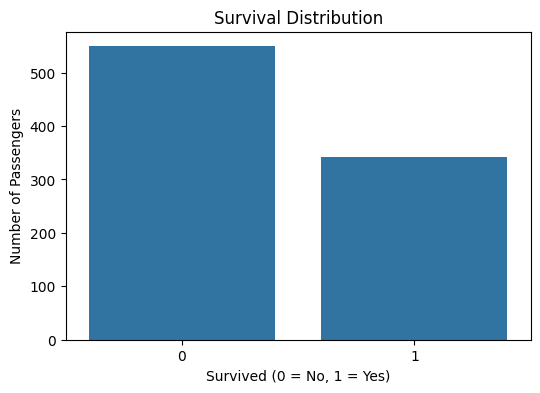

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Survived')

plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

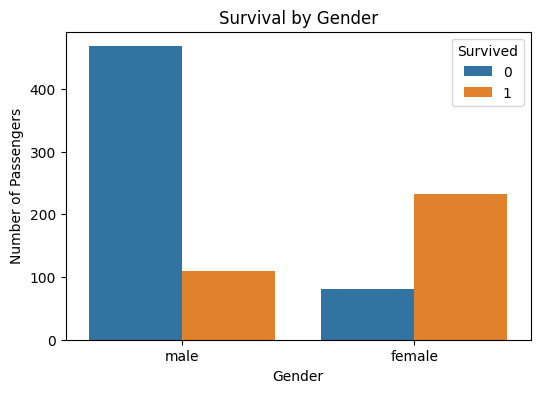

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

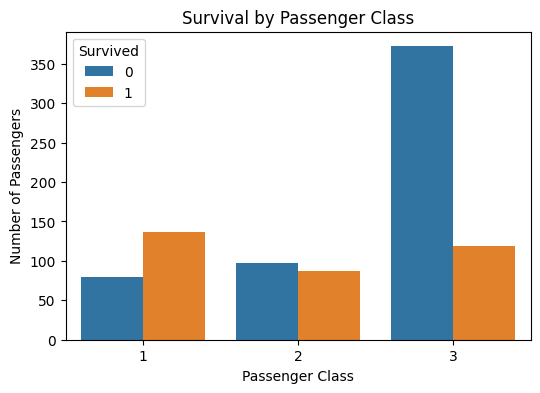

In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

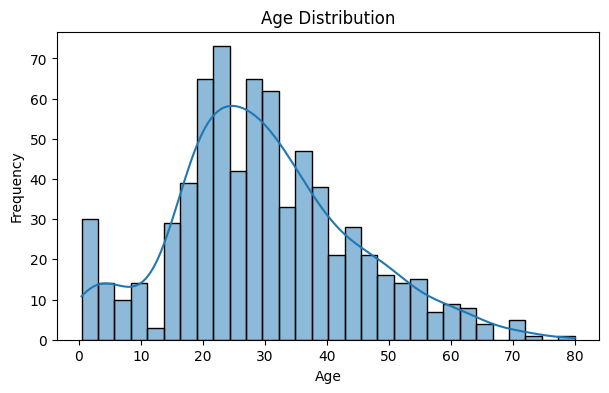

In [10]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

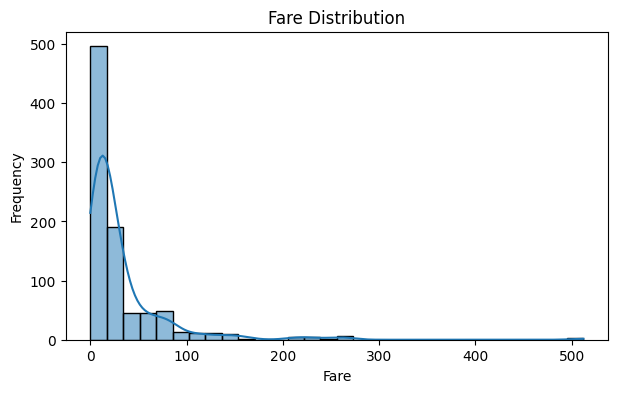

In [11]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x='Fare', bins=30, kde=True)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

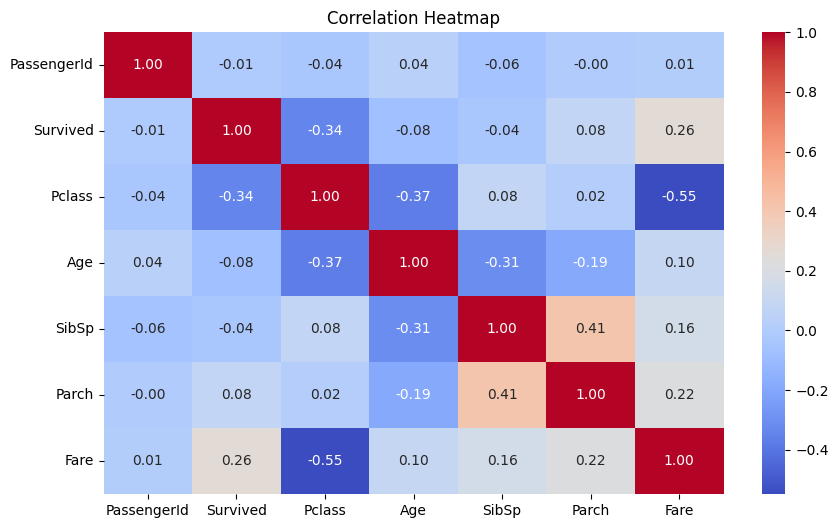

In [12]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [13]:
# Create a copy of original dataset
df_clean = df.copy()

# Fill missing Age with median
df_clean['Age'] = df_clean['Age'].fillna(
    df_clean['Age'].median()
)

# Fill missing Embarked with mode
df_clean['Embarked'] = df_clean['Embarked'].fillna(
    df_clean['Embarked'].mode()[0]
)

# Drop Cabin column
df_clean.drop('Cabin', axis=1, inplace=True)

print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDataset Shape After Cleaning:")
print(df_clean.shape)

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Dataset Shape After Cleaning:
(891, 11)


In [14]:
# Drop unnecessary columns
df_clean.drop(
    ['PassengerId', 'Name', 'Ticket'],
    axis=1,
    inplace=True
)

print("Dataset Shape:", df_clean.shape)

print("\nRemaining Columns:")
print(df_clean.columns.tolist())

display(df_clean.head())

Dataset Shape: (891, 8)

Remaining Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [15]:
# Apply One-Hot Encoding
df_clean = pd.get_dummies(
    df_clean,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print("Dataset After Encoding:")
display(df_clean.head())

print("\nDataset Shape:", df_clean.shape)

print("\nRemaining Data Types:")
print(df_clean.dtypes)

Dataset After Encoding:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1



Dataset Shape: (891, 9)

Remaining Data Types:
Survived        int64
Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Sex_male        int64
Embarked_Q      int64
Embarked_S      int64
dtype: object


In [16]:
# Separate independent and dependent variables

X = df_clean.drop('Survived', axis=1)

y = df_clean['Survived']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nIndependent Variables:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Features Shape: (891, 8)
Target Shape: (891,)

Independent Variables:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Target Variable:
Survived


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)



Training Features: (712, 8)
Testing Features: (179, 8)
Training Target: (712,)
Testing Target: (179,)


In [18]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nTraining Data Mean:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nTraining Data Standard Deviation:")
print(X_train_scaled.std(axis=0).round(2))


Training Data Shape: (712, 8)
Testing Data Shape: (179, 8)

Training Data Mean:
[-0.  0. -0. -0. -0. -0. -0.  0.]

Training Data Standard Deviation:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [20]:
# Initialize Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression Results")

print("\nAccuracy:", accuracy_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Logistic Regression Results

Accuracy: 0.8044692737430168

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Confusion Matrix:
[[98 12]
 [23 46]]


In [21]:
# Initialize knn

knn_model = KNeighborsClassifier(
    n_neighbors=5
)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

print("KNN Results")

print("\nAccuracy:", accuracy_score(y_test, knn_pred))

print("\nClassification Report:")
print(classification_report(y_test, knn_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

KNN Results

Accuracy: 0.8156424581005587

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179


Confusion Matrix:
[[98 12]
 [21 48]]


In [22]:
# Initialize Decision tree

dt_model = DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree Results")

print("\nAccuracy:", accuracy_score(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Decision Tree Results

Accuracy: 0.8212290502793296

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179


Confusion Matrix:
[[97 13]
 [19 50]]


In [23]:
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest Results")

print("\nAccuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results

Accuracy: 0.8156424581005587

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179


Confusion Matrix:
[[96 14]
 [19 50]]


In [24]:
svm_model = SVC(kernel='rbf')

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM Results")
print("\nAccuracy:", accuracy_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

SVM Results

Accuracy: 0.8100558659217877

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.93      0.86       110
           1       0.84      0.62      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179


Confusion Matrix:
[[102   8]
 [ 26  43]]


In [25]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, svm_pred)
    ],
    'Recall': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, svm_pred)
    ],
    'F1 Score': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, svm_pred)
    ]
})

print(results.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8045     0.7931  0.6667    0.7244
1                  KNN    0.8156     0.8000  0.6957    0.7442
2        Decision Tree    0.8212     0.7937  0.7246    0.7576
3        Random Forest    0.8156     0.7812  0.7246    0.7519
4                  SVM    0.8101     0.8431  0.6232    0.7167


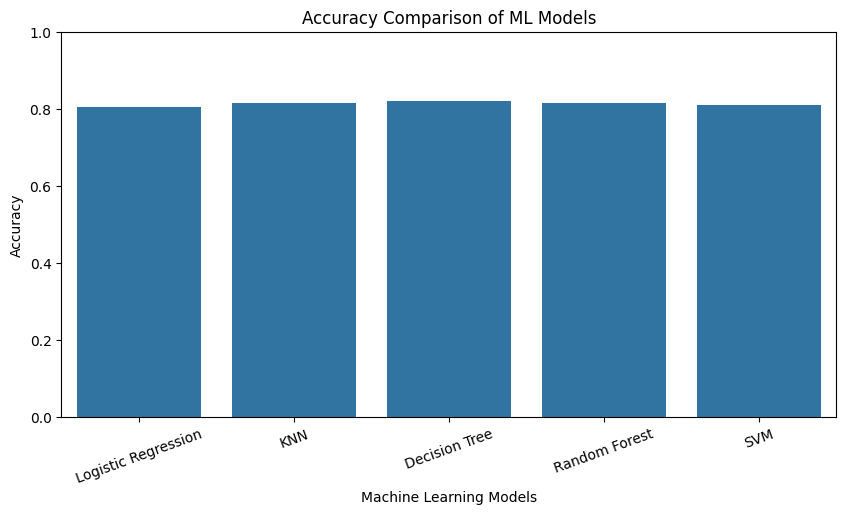

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of ML Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Final Model: Decision Tree
Accuracy: 0.8212290502793296

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



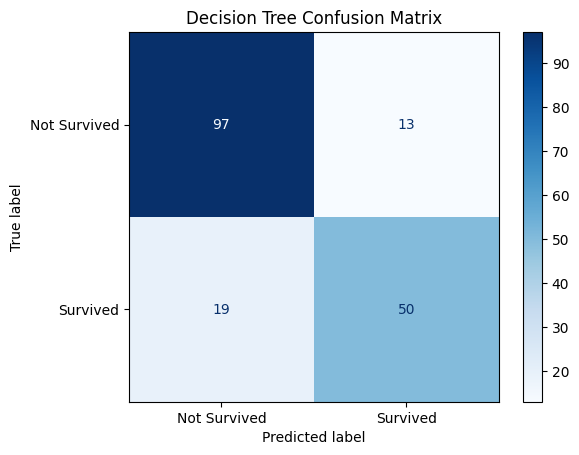

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

print("Final Model: Decision Tree")
print("Accuracy:", accuracy_score(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=['Not Survived', 'Survived'],
    cmap='Blues'
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [28]:
import joblib

# Save final Decision Tree model
joblib.dump(dt_model, 'titanic_decision_tree.pkl')

# Save model information and feature names
joblib.dump(X.columns.tolist(), 'titanic_features.pkl')

print("Final model saved successfully!")

Final model saved successfully!


In [29]:
from google.colab import files

files.download('titanic_decision_tree.pkl')
files.download('titanic_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import joblib

loaded_model = joblib.load('titanic_decision_tree.pkl')
features = joblib.load('titanic_features.pkl')

print("Model loaded successfully!")


Model loaded successfully!


In [31]:
new_passenger = pd.DataFrame([{
    'Pclass': 3,
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 7.25,
    'Sex_male': 1,
    'Embarked_Q': 0,
    'Embarked_S': 1
}])

# Ensure feature order matches training
new_passenger = new_passenger[features]

prediction = loaded_model.predict(new_passenger)[0]

probability = loaded_model.predict_proba(new_passenger)[0]

if prediction == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Not Survived")

print("Survival Probability:", round(probability[1] * 100, 2), "%")
print("Non-Survival Probability:", round(probability[0] * 100, 2), "%")

Prediction: Not Survived
Survival Probability: 0.0 %
Non-Survival Probability: 100.0 %
